# 🌐 Tema 6.3: Grafos Multiplex (Múltiples Relaciones)
Ejemplo didáctico: La Vida Universitaria.

### 1. El Problema del Grafo Simple (`nx.Graph`)
Intentemos modelar a dos estudiantes (Ana y Beto) que son compañeros de proyecto, pero que también juegan Valorant juntos en las noches.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Usamos el grafo tradicional que conocemos
G_simple = nx.Graph()

# Añadimos la relación académica
G_simple.add_edge('Ramiro', 'Cristobal', relacion='Proyecto Final')

# Añadimos la relación de gaming
G_simple.add_edge('Ramiro', 'Cristobal', relacion='Clash Royale')

print("Aristas en el grafo simple:")
print(G_simple.edges(data=True))

Aristas en el grafo simple:
[('Ramiro', 'Cristobal', {'relacion': 'Clash Royale'})]


### 2. La Solución: MultiGraph (El Grafo Multicapa)
Para modelar la complejidad humana, usamos `nx.MultiGraph`, que permite múltiples aristas paralelas entre los mismos dos nodos.

In [ ]:
# Instanciamos un Multigrafo
MG = nx.MultiGraph()

# Poblamos nuestro microcosmos universitario
MG.add_edge('Ramiro', 'Cristobal', relacion='Proyecto Final')
MG.add_edge('Ramiro', 'Cristobal', relacion='Clash Royale')
MG.add_edge('Beto', 'Carlos', relacion='Roomies')
MG.add_edge('Beto', 'Carlos', relacion='Clash Royale')
MG.add_edge('Carlos', 'Dani', relacion='Proyecto Final')

print("\n--- Todas las relaciones entre Ramiro y Cristobal ---")
display(MG['Ramiro']['Cristobal'])

print("\nNodos totales:", MG.number_of_nodes())
print("Aristas totales:", MG.number_of_edges())


--- Todas las relaciones entre Ramiro y Cristobal ---


AtlasView({0: {'relacion': 'Proyecto Final'}, 1: {'relacion': 'Clash Royale'}})


Nodos totales: 5
Aristas totales: 5


### 3. Diseccionando el Grafo (Slicing)
Si queremos saber quién es el mejor jugando Valorant, la relación de 'Roomies' o 'Proyecto' solo nos hace ruido. Debemos extraer (rebanar) esa capa específica.

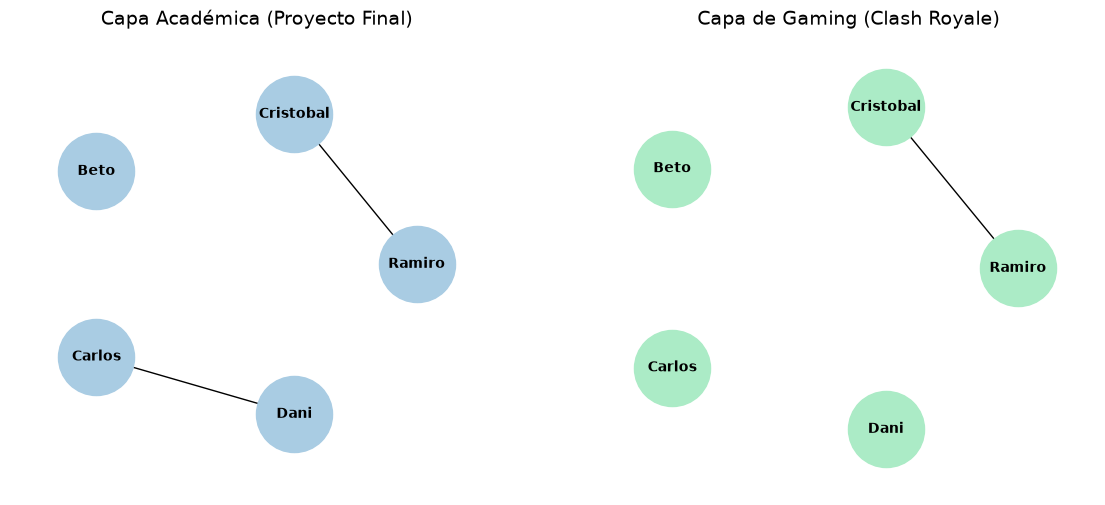

In [9]:
# Extraemos las capas
aristas_academicas = [(u, v) for u, v, d in MG.edges(data=True) if d['relacion'] == 'Proyecto Final']
G_academico = nx.Graph()
G_academico.add_nodes_from(MG.nodes()) # Aseguramos que todos los nodos existan aunque no tengan aristas aquí
G_academico.add_edges_from(aristas_academicas)

aristas_gaming = [(u, v) for u, v, d in MG.edges(data=True) if d['relacion'] == 'Clash Royale']
G_gaming = nx.Graph()
G_gaming.add_nodes_from(MG.nodes())
G_gaming.add_edges_from(aristas_gaming)

# 🛠️ EL TRUCO VISUAL PARA MULTIGRAFOS: 
# Calculamos la posición (pos) UNA SOLA VEZ basándonos en los 4 nodos. 
# circular_layout los pone en un cuadrado perfecto, evitando que se aglomeren.
pos_fija = nx.circular_layout(MG)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
# Usamos la 'pos_fija' y ajustamos márgenes para que los nodos no se corten en los bordes
nx.draw(G_academico, pos_fija, with_labels=True, node_color='#A9CCE3', node_size=3000, font_weight='bold', font_size=10)
plt.title('Capa Académica (Proyecto Final)', fontsize=14)
plt.margins(0.2) # Da un 20% de espacio extra en los bordes

plt.subplot(1, 2, 2)
nx.draw(G_gaming, pos_fija, with_labels=True, node_color='#ABEBC6', node_size=3000, font_weight='bold', font_size=10)
plt.title('Capa de Gaming (Clash Royale)', fontsize=14)
plt.margins(0.2)

plt.show()